# Mantenimiento por condición sobre NASA C-MAPSS FD001

**Pregunta de negocio:** ¿qué motores conviene intervenir ahora, y cuánto se ahorra frente a reemplazar por edad o dejar fallar?

Este notebook narra la evidencia generada por `python -m pm_survival study` (SPEC-003). No reentrena nada: lee `reports/landmark_FD001.json` y `reports/demo/`, así que corre sin los archivos NASA. Para regenerar las cifras desde los datos crudos, ejecuta el comando anterior con `--raw-dir`.

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
study = json.loads((ROOT / "reports" / "landmark_FD001.json").read_text(encoding="utf-8"))
pd.set_option("display.precision", 3)
print(f"{study['n_landmark_rows']} filas landmark · {len(study['sensors'])} sensores · CV {study['config']['n_repeats']}×{study['config']['n_folds']}")

3763 filas landmark · 14 sensores · CV 5×5


## 1. Del baseline a la condición actual

SPEC-001 resumía cada motor con sus **primeros 20 ciclos**. Eso evita filtrar el futuro, pero tira la señal: cerca de la falla es cuando los sensores cambian.

El modelo *landmark* resuelve ambas cosas: en cada inspección `c` mira **solo** los últimos 20 ciclos hasta `c` (media, pendiente y edad) y predice la vida **residual** `T − c`. Una prueba automática reescribe los datos posteriores a `c` y comprueba que los rasgos en `c` no cambian.

## 2. ¿Ordena bien qué motor fallará primero? (conjunto de prueba oficial)

,modelo,concordancia,IC 95 %,RMSE (ciclos),IC 95 % RMSE
0,Por condición (landmark),0.849,0.80–0.89,26.932,20.9–33.9
1,Solo edad (población),0.715,0.66–0.76,36.093,31.5–40.4
2,Ventana temprana (SPEC-001),0.688,0.63–0.74,44.155,38.4–50.1


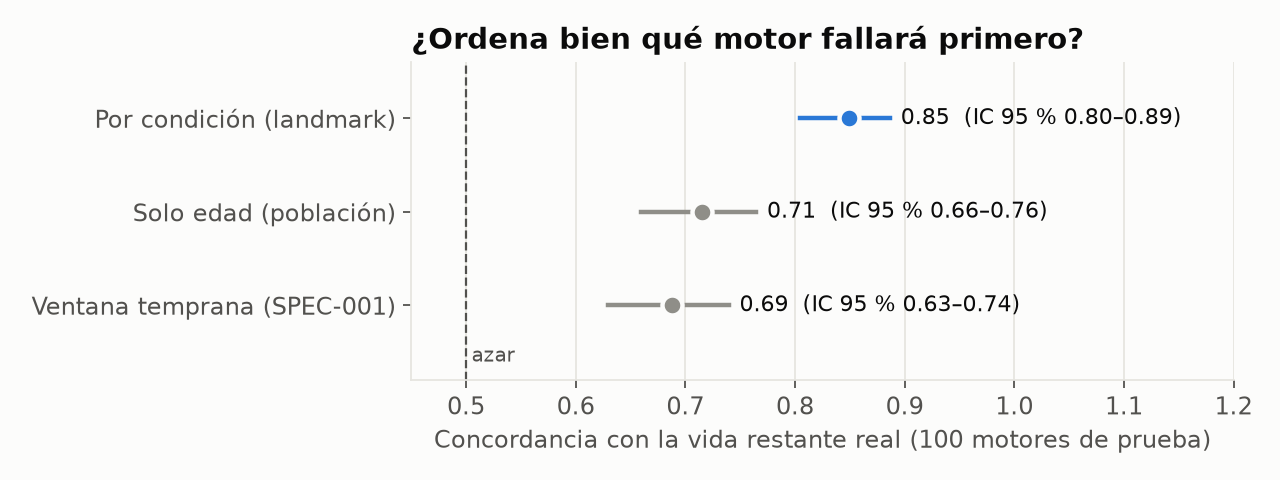

In [2]:
names = {"landmark": "Por condición (landmark)", "age_only": "Solo edad (población)", "early_window": "Ventana temprana (SPEC-001)"}
rows = []
for k, m in study["test"]["metrics"].items():
    rows.append({"modelo": names[k], "concordancia": m["concordance_vs_rul"],
                 "IC 95 %": f"{m['concordance_ci95'][0]:.2f}–{m['concordance_ci95'][1]:.2f}",
                 "RMSE (ciclos)": m["rmse_cycles"], "IC 95 % RMSE": f"{m['rmse_ci95'][0]:.1f}–{m['rmse_ci95'][1]:.1f}"})
display(pd.DataFrame(rows))
display(Image(ROOT / "reports" / "figures" / "test_concordance.png"))

**Lectura.** Usar solo la edad ya ordena mejor que el azar, porque los motores de prueba están truncados en momentos distintos. Las señales de los primeros 20 ciclos no aportan sobre la edad. La condición actual sí: la concordancia sube con intervalos que no se traslapan con las líneas base; el error en ciclos baja, aunque su intervalo se traslapa un poco con el de usar solo la edad.

## 3. ¿Las probabilidades significan lo que dicen?

,Brier modelo,Brier tasa base
horizonte (ciclos),,
10,0.021,0.050
30,0.028,0.134
50,0.046,0.195


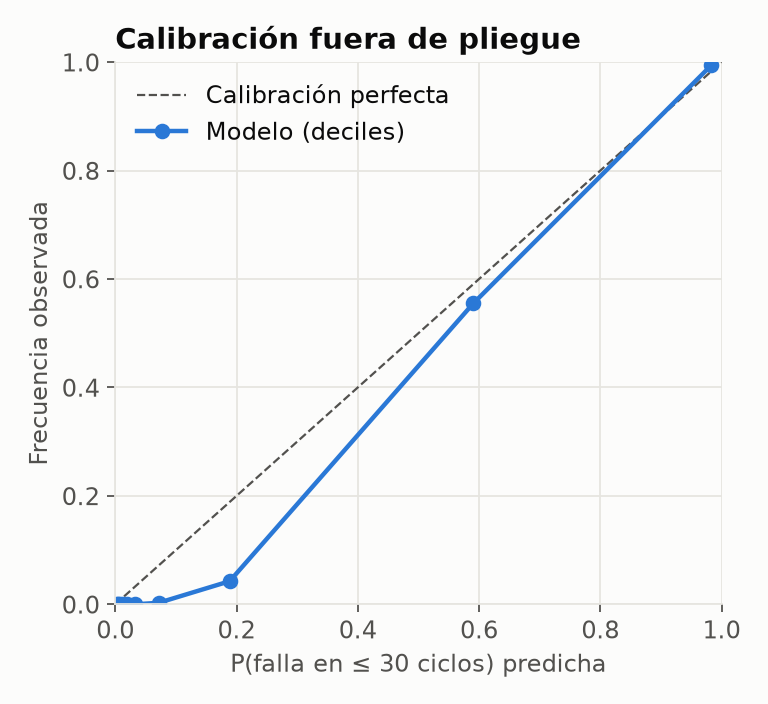

In [3]:
b = pd.DataFrame(study["cv"]["brier"]).T.rename(columns={"model": "Brier modelo", "base_rate": "Brier tasa base"})
b.index.name = "horizonte (ciclos)"
display(b)
display(Image(ROOT / "reports" / "figures" / "calibration_p30.png", width=420))

**Lectura.** El Brier queda muy por debajo de una predicción constante. La calibración es buena en los extremos, pero el modelo **sobrestima** el riesgo en la banda intermedia (predice ~19 % y se observa ~4 %). Para la decisión eso es conservador: adelanta algunos preventivos.

## 4. El número de negocio: costo por política

,política,cost_per_1000_cycles,failures,mean_wasted_cycles,utilisation
12,Dejar fallar,48.471,100.0,0.000,1.000
13,Por edad t*,9.639,0.0,102.570,0.503
14,Por condición,5.801,1.0,18.596,0.911
15,Oráculo (cota),4.922,0.0,3.160,0.985


Condición − edad con C_f/C_p = 10: **-3.84** por 1 000 ciclos (IC 95 % -4.49 a -2.77).

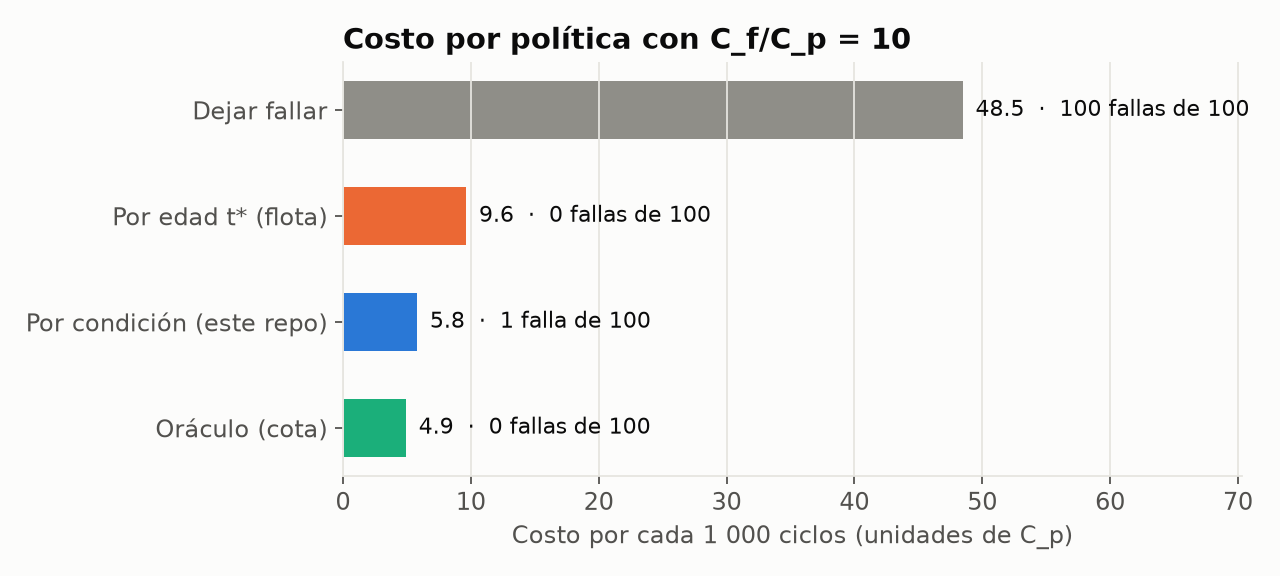

In [4]:
pol = pd.DataFrame(study["policies"])
label = {"run_to_failure": "Dejar fallar", "age": "Por edad t*", "condition": "Por condición", "oracle": "Oráculo (cota)"}
t10 = pol[pol["ratio"] == 10.0].assign(política=lambda d: d["policy"].map(label))
display(t10[["política", "cost_per_1000_cycles", "failures", "mean_wasted_cycles", "utilisation"]])
ci = study["policy_ci"]["10.0"]["condition_minus_age"]
display(Markdown(f"Condición − edad con C_f/C_p = 10: **{ci['diff']:.2f}** por 1 000 ciclos (IC 95 % {ci['ci_low']:.2f} a {ci['ci_high']:.2f})."))
display(Image(ROOT / "reports" / "figures" / "policy_cost_ratio10.png"))

**Cómo se calculó.** Backtest *renewal-reward* fuera de pliegue: cada motor de entrenamiento se evalúa con un modelo que no lo vio. El umbral de la política por condición se ajusta con una CV interna sobre los motores de entrenamiento, y t* con una Weibull de esos mismos motores. El oráculo (reemplazar en la última inspección antes de fallar) marca el techo alcanzable.

## 5. ¿Depende de los costos supuestos?

policy,run_to_failure,age,condition,oracle
ratio,,,,
2.0,9.694,7.370,5.326,4.922
3.0,14.541,7.526,5.433,4.922
5.0,24.235,8.018,5.535,4.922
10.0,48.471,9.639,5.801,4.922
20.0,96.941,11.417,6.333,4.922
50.0,242.354,14.143,7.930,4.922


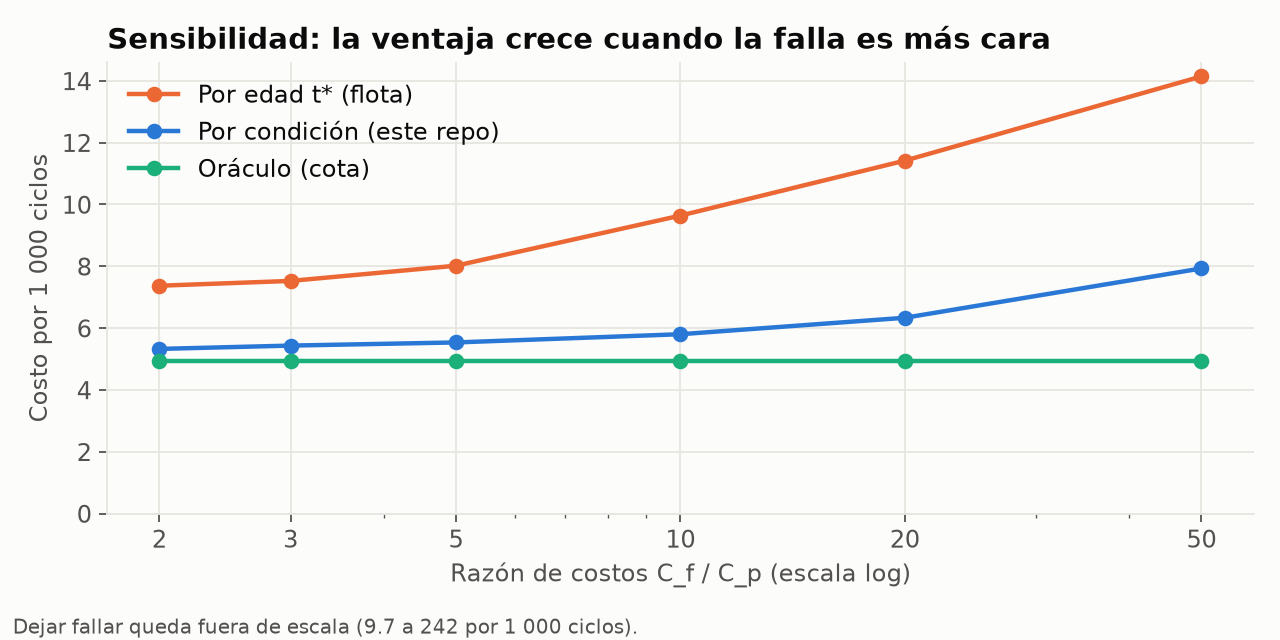

In [5]:
display(pol.pivot(index="ratio", columns="policy", values="cost_per_1000_cycles")[["run_to_failure", "age", "condition", "oracle"]])
display(Image(ROOT / "reports" / "figures" / "policy_sensitivity.png"))

**Lectura.** La política por condición es la más barata en todo el rango probado (C_f/C_p de 2 a 50) y su ventaja crece cuando la falla es más cara. El reemplazo por edad evita fallas, pero a costa de tirar en promedio unos 100 ciclos de vida por motor con C_f/C_p = 10.

## 6. Decisión para la flota actual

In [6]:
fleet = pd.read_csv(ROOT / "reports" / "demo" / "fleet_now.csv")
thr = json.loads((ROOT / "reports" / "demo" / "thresholds.json").read_text())["10.0"]
print(f"Umbral con C_f/C_p = 10: P(falla en ≤ 10 ciclos) ≥ {thr:.1%}")
display(fleet[fleet["p_fail_10"] >= thr].head(15))

Umbral con C_f/C_p = 10: P(falla en ≤ 10 ciclos) ≥ 7.3%


,unit_id,cycles_observed,p_fail_10,p_fail_30,median_remaining_cycles
0,82,162,0.560,1.000,9.442
1,76,205,0.507,1.000,9.932
2,34,203,0.472,1.000,10.279
3,81,213,0.465,1.000,10.357
4,68,187,0.358,1.000,11.647
5,42,156,0.342,1.000,11.877
6,100,198,0.327,1.000,12.097
7,20,184,0.284,1.000,12.827
8,31,196,0.228,0.999,13.978
9,49,303,0.169,0.991,15.682


## 7. Límites

- FD001 tiene un solo régimen de operación y un solo modo de falla; FD002–FD004 exigen reentrenar y revalidar.
- Los costos son ilustrativos y la inspección se supone gratuita y con datos completos.
- Son datos simulados por NASA; una planta real tiene ruido de medición, sensores caídos y mantenimientos imperfectos.
- El modelo no está promovido a producción.